# 100% Stacked Bar Chart

**Family:** Part-to-whole &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Part-to-whole:* Show how a single entity breaks down into its components.

## Design purpose

Stacked bars scaled so that each one totals 100%. Absolute size is removed, so readers compare the share of each component across groups.

## When to use

- Compare proportions across groups whose totals differ a lot
- Show how a mix changes across categories or periods
- Show survey answer shares by demographic group

## Avoid when

- The totals themselves matter (use a stacked bar or marimekko)
- There are many components, or components with tiny shares

## Alternatives

- Marimekko chart
- Diverging stacked bar (for ordered responses)
- Small-multiple pies

## Design tips

- Horizontal bars leave room for long group labels
- Label shares inside segments only when the segment is wide enough

## Example

Energy mix of electricity generation in five regions (synthetic shares).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
regions = ["North", "East", "South", "West", "Central"]
mix = pd.DataFrame({
    "Coal":    [35, 20, 45, 10, 28],
    "Gas":     [30, 35, 25, 30, 32],
    "Nuclear": [15, 25,  5, 10, 20],
    "Renewables": [20, 20, 25, 50, 20],
}, index=regions)
share = mix.div(mix.sum(axis=1), axis=0) * 100
share = share.sort_values("Renewables")
share.round(1)

,Coal,Gas,Nuclear,Renewables
North,35.0,30.0,15.0,20.0
East,20.0,35.0,25.0,20.0
Central,28.0,32.0,20.0,20.0
South,45.0,25.0,5.0,25.0
West,10.0,30.0,10.0,50.0


### Plot

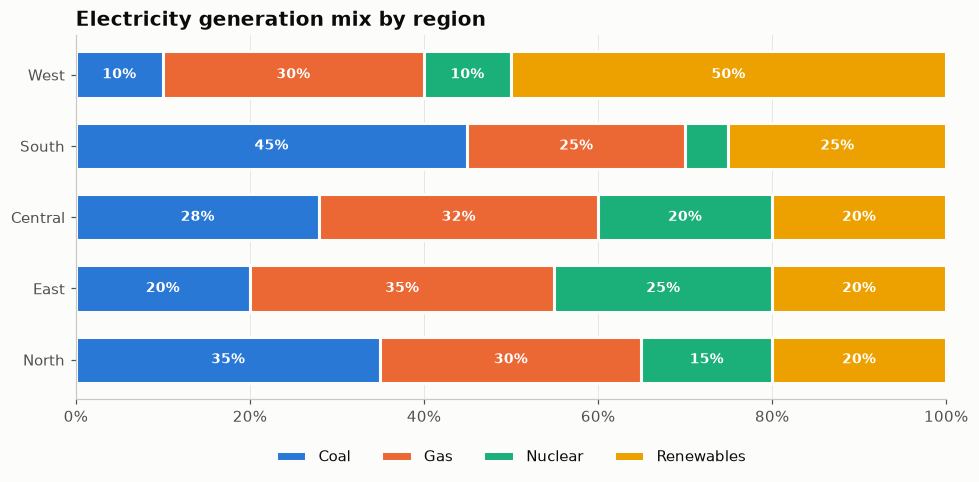

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
left = np.zeros(len(share))
for i, col in enumerate(share.columns):
    vals = share[col].values
    ax.barh(share.index, vals, left=left, color=PALETTE[i], label=col,
            height=0.65, edgecolor="#fcfcfb", linewidth=2)
    for y, (l, v) in enumerate(zip(left, vals)):
        if v >= 8:
            ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center",
                    fontsize=9, color="white", fontweight="bold")
    left += vals
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0f}%")
ax.set_title("Electricity generation mix by region")
ax.grid(axis="y", visible=False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
plt.show()

## How to read it

Each bar is 100% of a region's generation. Compare the width of one color, for example the amber renewables, between regions. The bars are sorted by renewable share, so West (50%) is on top.

---
Standalone script: [`percent_stacked_bar.py`](percent_stacked_bar.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)